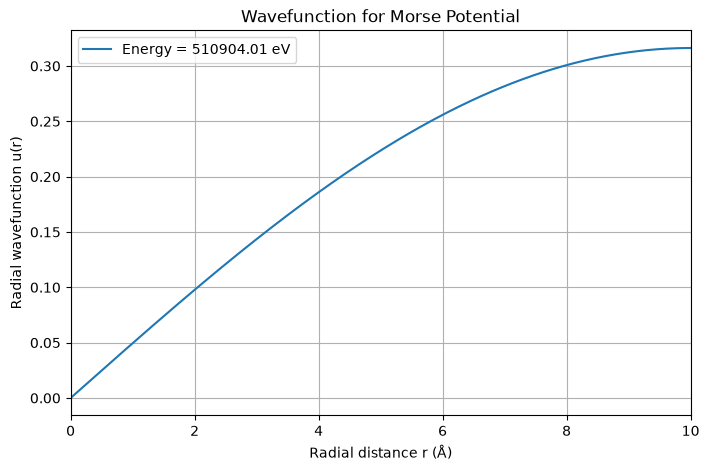

Energy = 510904.0103235539 eV


In [1]:

import numpy as np
import matplotlib.pyplot as plt

mc2 = 940e6
hbar_c = 197.3e6

D = 0.755501
alpha = 1.44
r0 = 0.131349

C = hbar_c**2 / (2 * mc2)

ri = 1e-4
rf = 20.0
N = 600

l = 0
state_index = 0

def r_prime(r):
    return (r - r0) / r

def morse_potential(r):
    rp = r_prime(r)
    V = D * (np.exp(-2 * alpha * rp) - np.exp(-alpha * rp))
    return V

def hamiltonian_matrix(r, dr):
    V = morse_potential(r)
    Veff = V + C * l * (l + 1) / r**2

    main = 2 * C / dr**2 + Veff
    side = -C / dr**2

    H = np.diag(main)
    H += np.diag(np.ones(N-1) * side, 1)
    H += np.diag(np.ones(N-1) * side, -1)

    return H

def solve():
    dr = (rf - ri) / (N + 1)
    r = ri + dr * np.arange(1, N + 1)

    H = hamiltonian_matrix(r, dr)

    energy, vectors = np.linalg.eigh(H)

    u = vectors[:, state_index]

    if u[np.argmax(np.abs(u))] < 0:
        u = -u

    u = np.concatenate(([0], u, [0]))

    norm = np.sqrt(np.sum(np.abs(u)**2) * dr)
    u = u / norm

    full_grid = np.concatenate(([ri], r, [rf]))

    return full_grid, u, energy[state_index]

r, u, E = solve()

plt.figure(figsize=(8, 5))
plt.plot(r, u, label=f"Energy = {E:.2f} eV")

plt.xlim(0, 10)
plt.xlabel("Radial distance r (Å)")
plt.ylabel("Radial wavefunction u(r)")
plt.title("Wavefunction for Morse Potential")

plt.grid(True)
plt.legend()
plt.show()

print("Energy =", E, "eV")
